# Финальный проект. NHL

Точные броски — shot-on-goal и goal. Незаблокированные броски —
shot-on-goal, goal и missed-shot.

## 1. Чтение данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rink import plot_rink

sns.set_context('notebook')
pd.set_option('float_format', '{:6.3f}'.format)

path = './'
events = pd.read_excel(path + 'NHL-playoffs-2026.xlsx', index_col=0)
events['Date'] = pd.to_datetime(events['Date'])

print(events.shape)
print(events.iloc[:10, [2, 3, 4, 9, 12]])
print('\nЧисло игр:', events['Game ID'].nunique())
print('\nТипы событий:')
print(events['Play Type'].value_counts())

(29710, 38)
        Date      Away Team       Home Team Remaining Time     Play Type
0 2026-04-19  Boston Bruins  Buffalo Sabres          20:00  period-start
1 2026-04-19  Boston Bruins  Buffalo Sabres          20:00       faceoff
2 2026-04-19  Boston Bruins  Buffalo Sabres          19:47           hit
3 2026-04-19  Boston Bruins  Buffalo Sabres          19:46           hit
4 2026-04-19  Boston Bruins  Buffalo Sabres          19:41           hit
5 2026-04-19  Boston Bruins  Buffalo Sabres          19:27           hit
6 2026-04-19  Boston Bruins  Buffalo Sabres          19:03           hit
7 2026-04-19  Boston Bruins  Buffalo Sabres          18:53   missed-shot
8 2026-04-19  Boston Bruins  Buffalo Sabres          18:48           hit
9 2026-04-19  Boston Bruins  Buffalo Sabres          18:37   missed-shot

Число игр: 82

Типы событий:
Play Type
hit                5621
faceoff            4995
shot-on-goal       4137
stoppage           3958
blocked-shot       2798
missed-shot        2643
g

Получилось 29 710 событий и 38 столбцов, как в задании. В файле 82 игры.
Встречаются 14 типов событий; чаще всего это силовые приёмы и вбрасывания.

## 2. Сводная таблица игр

In [2]:
games = events.groupby('Game ID').agg({
    'Date': 'first',
    'Away Team': 'first',
    'Home Team': 'first',
    'Cumulated Away Score': 'max',
    'Cumulated Home Score': 'max',
    'Period': 'max'
})
games.rename(columns={'Cumulated Away Score': 'Away Score',
                      'Cumulated Home Score': 'Home Score'}, inplace=True)
games['Overtimes'] = games['Period'] - 3

def outcome(n):
    if n == 0:
        return 'Final'
    elif n == 1:
        return 'Final/OT'
    else:
        return 'Final/' + str(n) + 'OT'

games['Outcome'] = games['Overtimes'].apply(outcome)
games = games[['Date', 'Away Team', 'Home Team', 'Away Score',
               'Home Score', 'Overtimes', 'Outcome']]
print(games.to_string())
print('\nЧисло игр по количеству овертаймов:')
print(games['Overtimes'].value_counts().sort_index())

                 Date             Away Team             Home Team  Away Score  Home Score  Overtimes    Outcome
Game ID                                                                                                        
2025030111 2026-04-19         Boston Bruins        Buffalo Sabres           3           4          0      Final
2025030112 2026-04-21         Boston Bruins        Buffalo Sabres           4           2          0      Final
2025030113 2026-04-23        Buffalo Sabres         Boston Bruins           3           1          0      Final
2025030114 2026-04-26        Buffalo Sabres         Boston Bruins           6           1          0      Final
2025030115 2026-04-28         Boston Bruins        Buffalo Sabres           2           1          1   Final/OT
2025030116 2026-05-01        Buffalo Sabres         Boston Bruins           4           1          0      Final
2025030121 2026-04-19    Montréal Canadiens   Tampa Bay Lightning           4           3          1   F

60 игр закончились в основное время, 18 — в первом овертайме, ещё 4 — во втором.
То есть дополнительное время понадобилось в 22 из 82 матчей, примерно в 26,8% игр.

## 3. Функция с информацией об игре

In [3]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return (f"{game['Home Team']} - {game['Away Team']} "
            f"({game['Home Score']} - {game['Away Score']}, "
            f"{game['Outcome']}, {game['Date'].strftime('%Y-%m-%d')})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Число голов за матч

In [4]:
games['Total Score'] = games['Away Score'] + games['Home Score']
print(games['Total Score'].describe())

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64


В среднем за матч забивали 5,927 шайбы, медиана равна 6.
Стандартное отклонение — 2,260. Минимум — 1 гол, максимум — 15,
а в центральных 50% матчей забивали от 5 до 7 голов.

## 5. Гистограмма числа голов

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64


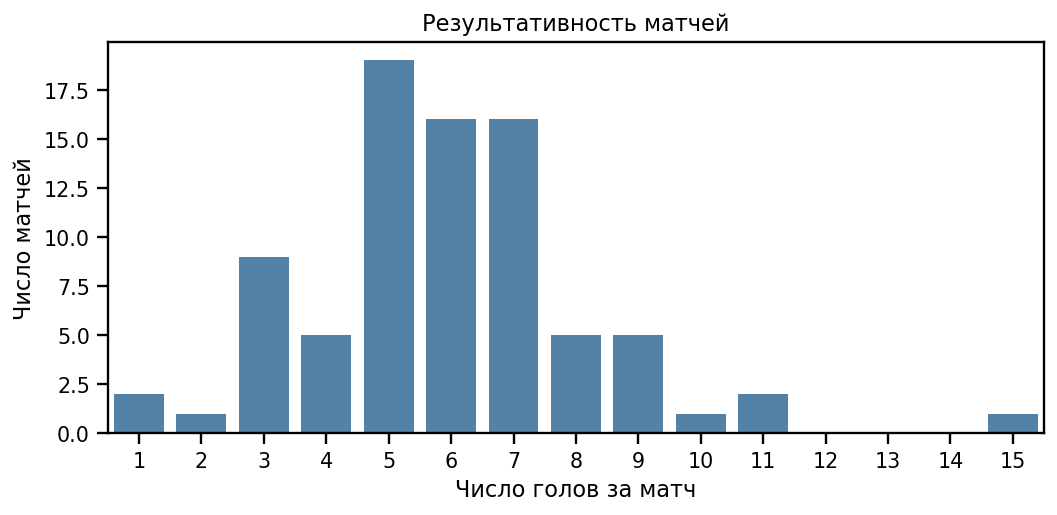

In [5]:
plt.figure(figsize=(8, 4))
sns.countplot(x='Total Score', data=games,
              order=range(games['Total Score'].min(), games['Total Score'].max() + 1),
              color='steelblue')
plt.xlabel('Число голов за матч')
plt.ylabel('Число матчей')
plt.title('Результативность матчей')
plt.tight_layout()
plt.show()

print(games['Total Score'].value_counts().sort_index())

Чаще всего забивали 5 голов: таких матчей 19. По 16 игр закончились
с 6 и 7 голами. Основная часть распределения находится около 5–7,
но есть отдельные очень результативные игры, из-за которых справа виден хвост.

## 6. Самые результативные и нерезультативные игры

In [6]:
least = games[games['Total Score'] == games['Total Score'].min()]
most = games[games['Total Score'] == games['Total Score'].max()]

print('Минимум голов:')
for gameId in least.index:
    print(gameInfo(gameId))
print('\nМаксимум голов:')
for gameId in most.index:
    print(gameInfo(gameId))

Минимум голов:
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)

Максимум голов:
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


Минимальная результативность была в двух матчах: Montréal Canadiens — Tampa Bay
Lightning и Philadelphia Flyers — Pittsburgh Penguins, оба завершились 0:1
или 1:0 в овертайме. Максимум — 15 шайб в игре Colorado Avalanche — Minnesota
Wild со счётом 9:6.

## 7. Число игроков в каждом матче

In [7]:
away_cols = ["Away Team's Player on the Ice #" + str(i) for i in range(1, 7)]
home_cols = ["Home Team's Player on the Ice #" + str(i) for i in range(1, 7)]
player_cols = away_cols + home_cols + ["Away Team's Goalie", "Home Team's Goalie"]

players = events.set_index('Game ID')[player_cols].stack().reset_index()
players.columns = ['Game ID', 'Column', 'Player']
players = players[['Game ID', 'Player']].drop_duplicates()
player_count = players.groupby('Game ID')['Player'].nunique()

maxplayers = pd.DataFrame({'Player Count': player_count})
maxplayers = maxplayers[maxplayers['Player Count'] == player_count.max()]
maxplayers['Game Info'] = [gameInfo(i) for i in maxplayers.index]
print(maxplayers[['Game Info', 'Player Count']].to_string())

gameId = player_count.idxmax()
game = events[events['Game ID'] == gameId]
print('\nГости:', game[away_cols + ["Away Team\'s Goalie"]].stack().nunique())
print('Хозяева:', game[home_cols + ["Home Team\'s Goalie"]].stack().nunique())

                                                                 Game Info  Player Count
Game ID                                                                                 
2025030216  Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)            40

Гости: 20
Хозяева: 20


Больше всего игроков было в матче Montréal Canadiens — Buffalo Sabres
16 мая: 40 человек, по 20 с каждой стороны. В примере задания указано 41,
но в приложенном файле получается 40 уникальных непустых имён.

## 8. Расстояние броска до ворот

In [8]:
shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()
xcol = 'X Coordinate on the Ice Rink'
ycol = 'Y Coordinate on the Ice Rink'

home_shot = shots['Team Making the Play'] == shots['Home Team']
home_left = shots["Home Team's Defending Side"] == 'left'
shots['Goal X'] = -89
shots.loc[(home_shot & home_left) | (~home_shot & ~home_left), 'Goal X'] = 89

dy = np.maximum(shots[ycol].abs() - 3, 0)
shots['Shot Length'] = np.sqrt((shots[xcol] - shots['Goal X']) ** 2 + dy ** 2)
events['Shot Length'] = shots['Shot Length']
shots['Shot'] = 'on goal'
shots.loc[shots['Play Type'] == 'missed-shot', 'Shot'] = 'missed'

print(shots[['Game ID', 'Play Type', 'Shot Length']])
print('\nПропуски в координатах и стороне защиты:')
print(shots[[xcol, ycol, "Home Team's Defending Side"]].isna().sum())

          Game ID     Play Type  Shot Length
7      2025030111   missed-shot       12.207
9      2025030111   missed-shot       12.000
12     2025030111   missed-shot       29.411
13     2025030111  shot-on-goal       62.169
19     2025030111   missed-shot       52.924
...           ...           ...          ...
29695  2025030416   missed-shot       54.083
29696  2025030416   missed-shot        5.099
29704  2025030416          goal       46.239
29706  2025030416   missed-shot       60.926
29707  2025030416  shot-on-goal       49.041

[7266 rows x 3 columns]

Пропуски в координатах и стороне защиты:
X Coordinate on the Ice Rink    0
Y Coordinate on the Ice Rink    0
Home Team's Defending Side      0
dtype: int64


Всего получилось 7 266 незаблокированных бросков. У выбранных событий нет
пропусков координат или стороны защиты, поэтому расстояния можно посчитать
для всех. Первые значения совпадают с примером в условии: 12,207; 12,000;
29,411 фута.

## 9. Распределения длины точных и неточных бросков

           count   mean    std    min    25%    50%    75%     max
Shot                                                              
missed  2643.000 34.014 22.313  0.000 16.155 32.249 49.041 185.068
on goal 4623.000 36.207 29.997  0.000 15.000 31.828 47.011 188.215

Броски длиной более 89 футов:
Play Type
shot-on-goal    202
missed-shot      30
goal             19
Name: count, dtype: int64


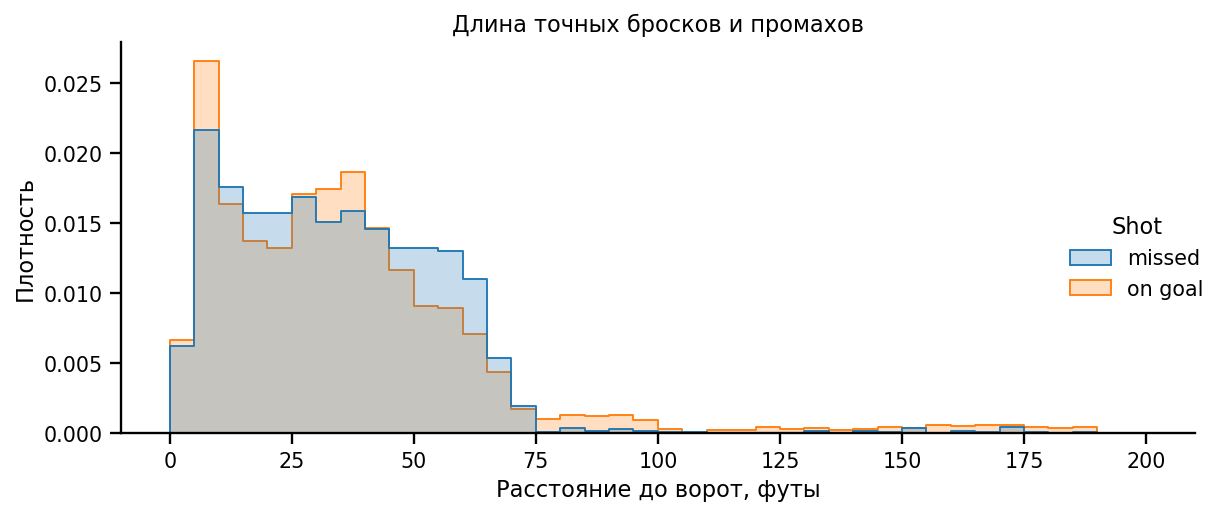

In [9]:
sns.displot(data=shots, x='Shot Length', hue='Shot',
            hue_order=['missed', 'on goal'],
            bins=np.arange(0, 201, 5), stat='density', common_norm=False,
            element='step', height=4, aspect=2)
plt.xlabel('Расстояние до ворот, футы')
plt.ylabel('Плотность')
plt.title('Длина точных бросков и промахов')
plt.tight_layout()
plt.show()

print(shots.groupby('Shot')['Shot Length'].describe())
print('\nБроски длиной более 89 футов:')
print(shots[shots['Shot Length'] > 89]['Play Type'].value_counts())

Распределения сильно пересекаются. Медианы почти одинаковые: 31,828 фута
для точных бросков и 32,249 для промахов. Среднее у точных даже больше:
36,207 против 34,014 фута. На него влияет длинный правый хвост, поэтому
по одному среднему нельзя сказать, что точные броски обычно делаются дальше.

Предполагаю, что часть дальних попаданий — это выбросы шайбы из своей зоны,
которые доходят до вратаря, и попытки забить в пустые ворота в конце матча.
При выбросе вратарь может остановить шайбу, и событие попадёт в shot-on-goal.
Среди бросков длиннее 89 футов есть 202 shot-on-goal, 30 промахов и 19 голов.
Значит, объяснять весь хвост только голами в пустые ворота было бы неверно.
Это возможное объяснение, а не установленная причина каждого такого события.

## 10. Доля точных бросков команды за матч

In [10]:
numshots = shots.groupby(['Game ID', 'Team Making the Play', 'Shot']).size()
numshots = numshots.unstack(fill_value=0)
numshots['Share of Shots on Goal'] = numshots['on goal'] / (numshots['on goal'] + numshots['missed'])

print(numshots[['Share of Shots on Goal']].to_string())
print('\nОписательные статистики доли:')
print(numshots['Share of Shots on Goal'].describe())

Shot                             Share of Shots on Goal
Game ID    Team Making the Play                        
2025030111 Boston Bruins                          0.625
           Buffalo Sabres                         0.679
2025030112 Boston Bruins                          0.614
           Buffalo Sabres                         0.636
2025030113 Boston Bruins                          0.694
           Buffalo Sabres                         0.682
2025030114 Boston Bruins                          0.600
           Buffalo Sabres                         0.648
2025030115 Boston Bruins                          0.630
           Buffalo Sabres                         0.491
2025030116 Boston Bruins                          0.667
           Buffalo Sabres                         0.634
2025030121 Montréal Canadiens                     0.655
           Tampa Bay Lightning                    0.622
2025030122 Montréal Canadiens                     0.659
           Tampa Bay Lightning                  

Получилось 164 наблюдения: по две команды на каждую из 82 игр. Доли заметно
меняются от матча к матчу. Поэтому результат одной игры сам по себе ещё
не показывает обычную точность команды. Этот показатель также не равен
реализации бросков в голы: отбитая вратарём шайба здесь считается точным броском.

## 11. Команды с высокой и низкой средней точностью

In [11]:
avgnumshots = numshots['Share of Shots on Goal'].groupby(level='Team Making the Play').mean()
print('Самые высокие средние доли:')
print(avgnumshots.nlargest(5))
print('\nСамые низкие средние доли:')
print(avgnumshots.nsmallest(5))

Самые высокие средние доли:
Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

Самые низкие средние доли:
Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64


Самая высокая средняя доля у Edmonton Oilers — 70,6%, затем идут
Philadelphia Flyers — 68,4% и Dallas Stars — 67,0%. Самая низкая у
Pittsburgh Penguins — 55,4%, далее Utah Mammoth — 59,9% и Carolina Hurricanes — 61,5%.
Более высокая точность сама по себе не гарантирует больше голов или побед:
важны ещё число бросков, их опасность и игра вратаря соперника. Команды также
провели разное число матчей и играли с разными соперниками.

## 12. Среднее число бросков в створ и голов

In [12]:
goals = events[events['Play Type'] == 'goal'].copy()
goals_by_game = goals.groupby(['Game ID', 'Team Making the Play']).size()

teamstats = numshots[['on goal']].rename(columns={'on goal': 'Shot'})
teamstats['Goal'] = goals_by_game
teamstats['Goal'] = teamstats['Goal'].fillna(0)
avgshots = teamstats.groupby(level='Team Making the Play').mean()

print(avgshots.to_string())

Shot                   Shot   Goal
Team Making the Play              
Anaheim Ducks        31.667  3.250
Boston Bruins        25.167  2.000
Buffalo Sabres       30.462  3.308
Carolina Hurricanes  31.632  3.474
Colorado Avalanche   32.154  3.385
Dallas Stars         31.000  2.500
Edmonton Oilers      28.333  3.500
Los Angeles Kings    25.250  1.250
Minnesota Wild       28.727  3.727
Montréal Canadiens   23.263  2.842
Ottawa Senators      27.500  1.250
Philadelphia Flyers  24.600  2.100
Pittsburgh Penguins  26.500  1.833
Tampa Bay Lightning  28.000  2.143
Utah Mammoth         27.833  3.000
Vegas Golden Knights 26.545  3.455


Больше всего бросков в створ в среднем у Colorado Avalanche — 32,154 за
матч. Больше всего голов у Minnesota Wild — 3,727. У Montréal Canadiens
минимум бросков в створ — 23,263, но по голам команда не последняя.
Меньше всего голов у Los Angeles Kings и Ottawa Senators — по 1,250 за матч.
Уже по таблице видно, что число бросков и число голов связаны не полностью.

## 13. Связь бросков и голов

Корреляция: 0.5207961205304794


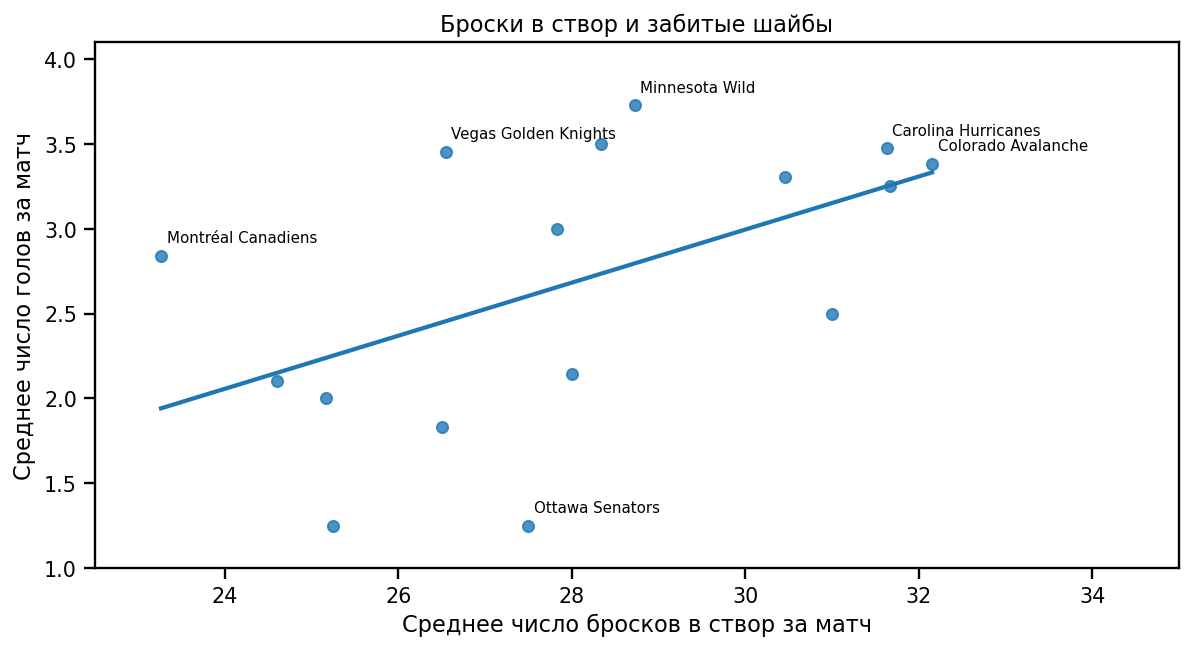

In [13]:
plt.figure(figsize=(9, 5))
sns.regplot(x='Shot', y='Goal', data=avgshots, ci=None)
for team in ['Minnesota Wild', 'Carolina Hurricanes', 'Colorado Avalanche',
             'Montréal Canadiens', 'Ottawa Senators', 'Vegas Golden Knights']:
    plt.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']),
                 xytext=(3, 7), textcoords='offset points', fontsize=8)
plt.xlabel('Среднее число бросков в створ за матч')
plt.ylabel('Среднее число голов за матч')
plt.title('Броски в створ и забитые шайбы')
plt.xlim(22.5, 35)
plt.ylim(1, 4.1)
plt.tight_layout()
plt.show()

print('Корреляция:', avgshots['Shot'].corr(avgshots['Goal']))

Связь положительная, но точки находятся довольно далеко от линии.
Корреляция равна примерно 0,521: команды с большим средним числом бросков
обычно забивают больше, но зависимость не строгая. Например, Vegas Golden
Knights забивают много при сравнительно небольшом числе бросков.
Здесь всего 16 наблюдений, это средние по командам, поэтому такой график
не доказывает причинную связь и не описывает отдельно каждый матч.

## 14. Матч с наибольшим числом попыток броска

In [14]:
allshots = events[events['Play Type'].isin(['goal', 'shot-on-goal',
                                         'missed-shot', 'blocked-shot'])].copy()
shot_count = allshots.groupby('Game ID').size()
idxmax = shot_count.idxmax()
print(gameInfo(idxmax))
print('Всего попыток броска:', shot_count.loc[idxmax])
print('\nПо исходам:')
print(allshots[allshots['Game ID'] == idxmax]['Play Type'].value_counts())

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Всего попыток броска: 208

По исходам:
Play Type
shot-on-goal    83
missed-shot     66
blocked-shot    54
goal             5
Name: count, dtype: int64


Максимум — 208 попыток в игре Carolina Hurricanes — Ottawa Senators
20 апреля, счёт 3:2 после двух овертаймов. Длинная продолжительность игры
помогает объяснить большое общее число бросков. Это не обязательно матч
с самым высоким темпом бросков в расчёте на минуту.

## 15. Броски на хоккейной площадке

Сторона защиты хозяев по периодам:
Period
1    right
2     left
3    right
4     left
5    right
Name: Home Team's Defending Side, dtype: object


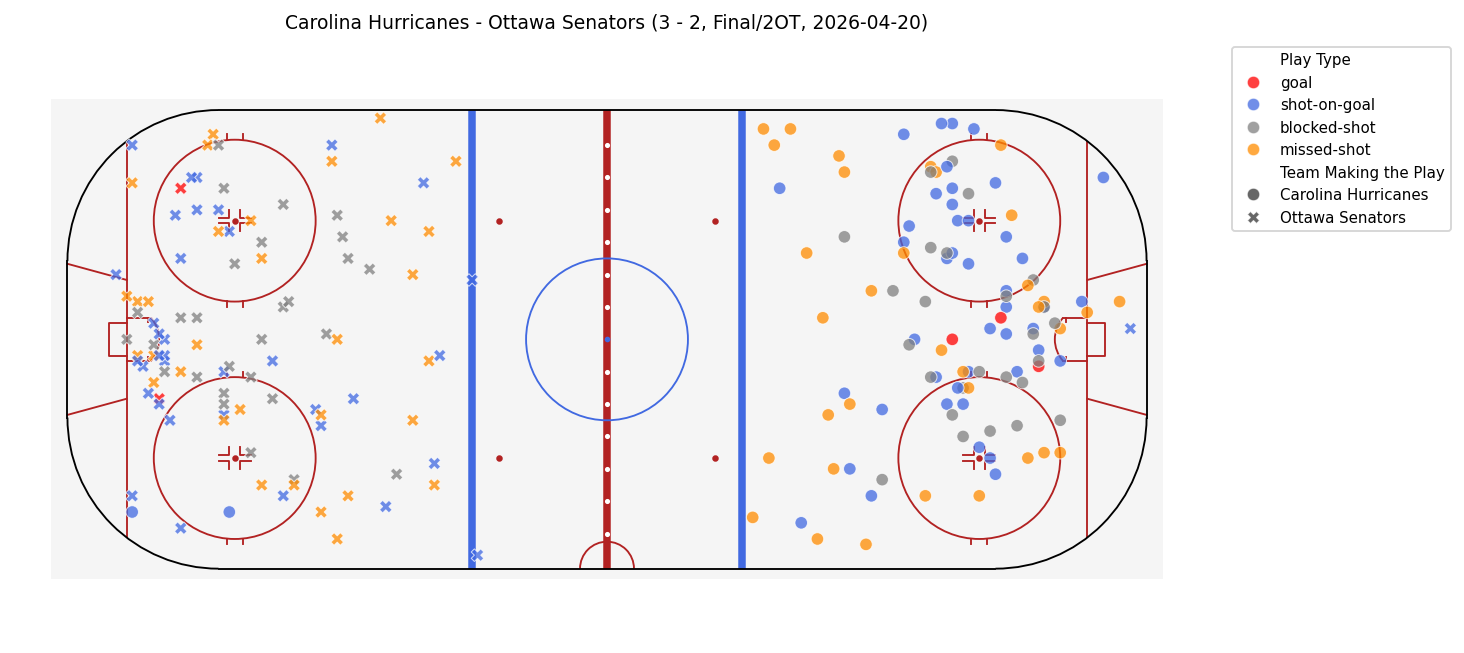

In [15]:
game_shots = allshots[allshots['Game ID'] == idxmax].copy()
print('Сторона защиты хозяев по периодам:')
print(game_shots.groupby('Period')["Home Team's Defending Side"].first())
odd = game_shots['Period'] % 2 == 1
game_shots.loc[odd, [xcol, ycol]] = -game_shots.loc[odd, [xcol, ycol]]

plt.figure(figsize=(11, 5))
plot_rink()
sns.scatterplot(x=xcol, y=ycol, data=game_shots,
                hue='Play Type', style='Team Making the Play',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette=['red', 'royalblue', 'gray', 'darkorange'],
                s=45, alpha=.75)
plt.axis('equal')
plt.axis('off')
plt.title(gameInfo(idxmax), fontsize=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

Большинство попыток расположено в зоне атаки около ворот соперника.
Броски разных исходов пересекаются по расположению, поэтому одна точка
броска ещё не определяет его результат. Карта показывает и отдельные дальние
попытки со своей половины. После поворота направление атаки каждой команды
одинаково во всех периодах.

## 16. Десять лучших по голам

In [16]:
scorers = goals['Player in the Event #1'].value_counts()
print(scorers.nlargest(10).to_string())

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Jordan Staal         8
Nikolaj Ehlers       8
Nathan MacKinnon     7
Taylor Hall          7
Mark Stone           7
Jackson Blake        7


Первый по числу голов — Brett Howden с 14 шайбами, затем Pavel Dorofeyev
с 12 и Logan Stankoven с 11. Это суммарные голы за плей-офф, поэтому на
результат влияет и то, сколько игр провела команда игрока.

## 17. Десять лучших по голевым передачам

In [17]:
assists = pd.concat([goals['Player in the Event #2'],
                     goals['Player in the Event #3']]).value_counts()
print(assists.nlargest(10).to_string())

Jack Eichel        20
Mitch Marner       19
Jackson Blake      13
Lane Hutson        13
Taylor Hall        12
Martin Necas       12
Nick Suzuki        12
Shea Theodore      12
Quinn Hughes       11
Kirill Kaprizov    11


Больше всего передач у Jack Eichel — 20, у Mitch Marner — 19.
Следующие значения заметно ниже: у Jackson Blake и Lane Hutson по 13.

## 18. Десять лучших по системе «гол плюс пас»

In [18]:
points = pd.DataFrame({'Goals': scorers, 'Assists': assists}).fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']
print(points.nlargest(10, 'Points').to_string())

                 Goals  Assists  Points
Mitch Marner        10       19      29
Jack Eichel          2       20      22
Jackson Blake        7       13      20
Taylor Hall          7       12      19
Brett Howden        14        4      18
Nikolaj Ehlers       8       10      18
Shea Theodore        6       12      18
Lane Hutson          3       13      16
Logan Stankoven     11        5      16
Nick Suzuki          4       12      16


По очкам лидирует Mitch Marner: 10 голов и 19 передач, всего 29 очков.
На втором месте Jack Eichel с 22, на третьем Jackson Blake с 20.
Лидер по голам не обязан лидировать по сумме очков: передачи могут заметно
изменить порядок игроков.

## 19. Броски в створ в среднем за игру у игроков

In [19]:
played_games = players.groupby('Player')['Game ID'].nunique()
player_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
player_shots = player_shots['Player in the Event #1'].value_counts()
shot_leaders = pd.DataFrame({'Games': played_games, 'Shots': player_shots})
shot_leaders['Shots'] = shot_leaders['Shots'].fillna(0).astype(int)
shot_leaders['Shots per Game'] = shot_leaders['Shots'] / shot_leaders['Games']
print(shot_leaders.nlargest(10, 'Shots per Game').to_string())

                  Games  Shots  Shots per Game
Jason Robertson       6     30           5.000
Dylan Guenther        6     27           4.500
Nikita Kucherov       7     31           4.429
Matt Boldy           11     48           4.364
Quinton Byfield       4     17           4.250
Darren Raddysh        7     28           4.000
Joel Eriksson Ek      6     24           4.000
Alex Laferriere       4     15           3.750
David Pastrnak        6     22           3.667
Nathan MacKinnon     13     47           3.615


Первое место у Jason Robertson — 5,000 броска в створ за матч.
Далее Dylan Guenther — 4,500 и Nikita Kucherov — 4,429. Такой рейтинг
отличается от суммарного: игрок может провести мало игр, но часто бросать
в каждой из них. Поэтому смотреть на столбец Games тоже нужно.

## 20. Силовые приёмы в среднем за игру

In [20]:
player_hits = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()
hit_leaders = pd.DataFrame({'Games': played_games, 'Hits': player_hits})
hit_leaders['Hits'] = hit_leaders['Hits'].fillna(0).astype(int)
hit_leaders['Hits per Game'] = hit_leaders['Hits'] / hit_leaders['Games']
print(hit_leaders.nlargest(10, 'Hits per Game').to_string())

                    Games  Hits  Hits per Game
Lawson Crouse           6    38          6.333
Alex Turcotte           1     6          6.000
Alexander Petrovic      1     6          6.000
Yakov Trenin            9    51          5.667
Dylan Cozens            4    22          5.500
Vasily Podkolzin        6    32          5.333
Carl Grundstrom         3    15          5.000
Ivan Barbashev         22   110          5.000
Marcus Foligno         11    55          5.000
Owen Tippett            6    29          4.833


Лидирует Lawson Crouse — 6,333 силового приёма за матч.
У Alex Turcotte и Alexander Petrovic по 6,000. У игроков разное число
матчей, поэтому большие средние на коротком отрезке стоит оценивать осторожно.

## 21. Вратари, не пропустившие хотя бы в одной игре

У всех 22 решающих голов в овертайме отсутствуют составы обеих команд
и имена вратарей. Для этих строк использованы вратари из предыдущего
события той же игры. Допущение: между событиями вратаря не заменили.
Пропуски вратарей при заполненном составе оставлены как есть —
вратарь мог быть снят.

In [21]:
goalie_events = events.sort_values(['Game ID', 'Play ID']).copy()
empty_goal = ((goalie_events['Play Type'] == 'goal') &
              goalie_events[away_cols + home_cols].isna().all(axis=1))
print('Голов без обоих составов:', empty_goal.sum())

for side in ['Away', 'Home']:
    col = side + " Team's Goalie"
    previous = goalie_events.groupby('Game ID')[col].shift()
    goalie_events.loc[empty_goal, col] = previous.loc[empty_goal]

goalie_games = []
conceded = []
for side, opponent in [('Away', 'Home'), ('Home', 'Away')]:
    col = side + " Team's Goalie"
    appearances = goalie_events[['Game ID', col]].dropna().drop_duplicates()
    appearances.columns = ['Game ID', 'Goalie']
    goalie_games.append(appearances)

    against = goalie_events[(goalie_events['Play Type'] == 'goal') &
                            (goalie_events['Team Making the Play'] == goalie_events[opponent + ' Team'])]
    against = against[['Game ID', col]].dropna()
    against.columns = ['Game ID', 'Goalie']
    conceded.append(against)

goalie_games = pd.concat(goalie_games).drop_duplicates().set_index(['Game ID', 'Goalie'])
conceded = pd.concat(conceded).groupby(['Game ID', 'Goalie']).size()
goalie_games['Goals Against'] = conceded
goalie_games['Goals Against'] = goalie_games['Goals Against'].fillna(0).astype(int)
zero_games = goalie_games[goalie_games['Goals Against'] == 0].reset_index()
zero_goalies = sorted(zero_games['Goalie'].unique())

print('\nВратари:')
for goalie in zero_goalies:
    print(goalie)

zero_games['Game Info'] = zero_games['Game ID'].apply(gameInfo)
print('\nМатчи без пропущенных голов у этих вратарей:')
print(zero_games[['Goalie', 'Goals Against', 'Game Info']].to_string(index=False))

Голов без обоих составов: 22

Вратари:
Andrei Vasilevskiy
Brandon Bussi
Dan Vladar
Frederik Andersen
Joonas Korpisalo
Scott Wedgewood

Матчи без пропущенных голов у этих вратарей:
            Goalie  Goals Against                                                               Game Info
Andrei Vasilevskiy              0  Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
        Dan Vladar              0    Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)
 Frederik Andersen              0     Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)
     Brandon Bussi              0   Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)
  Joonas Korpisalo              0               Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)
 Frederik Andersen              0        Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)
        Dan Vladar              0 Philadelphia Flyers - Pittsburgh Penguins (1

Получилось шесть вратарей: Andrei Vasilevskiy, Brandon Bussi, Dan Vladar,
Frederik Andersen, Joonas Korpisalo и Scott Wedgewood. В таблице девять
пар «игра — вратарь», потому что у некоторых таких игр несколько.
Это список по критерию задания, а не список официальных полных сухих матчей.
Например, Joonas Korpisalo не пропустил после выхода на замену в игре,
в которой Boston Bruins проиграли 1:6.

Без обработки пустых составов результат был бы неверным. Например,
Brandon Bussi получил бы ноль пропущенных в третьем матче финала,
хотя Carolina проиграла после гола во втором овертайме. При допущении
о неизменном вратаре этот гол относится к нему. Если в исходных данных
есть незафиксированная замена прямо перед голом, результат этого пункта
нужно уточнить по более полным данным.

## 22. Свой вопрос: чаще ли выигрывали хозяева?

Побед хозяев: 39
Побед гостей: 43
Доля побед хозяев: 0.47560975609756095

Среднее число голов:
Home Score    2.805
Away Score    3.122
dtype: float64

Отдельно по наличию овертайма:
          Games  Home Wins  Home Win Share
Overtime                                  
False        60         25           0.417
True         22         14           0.636


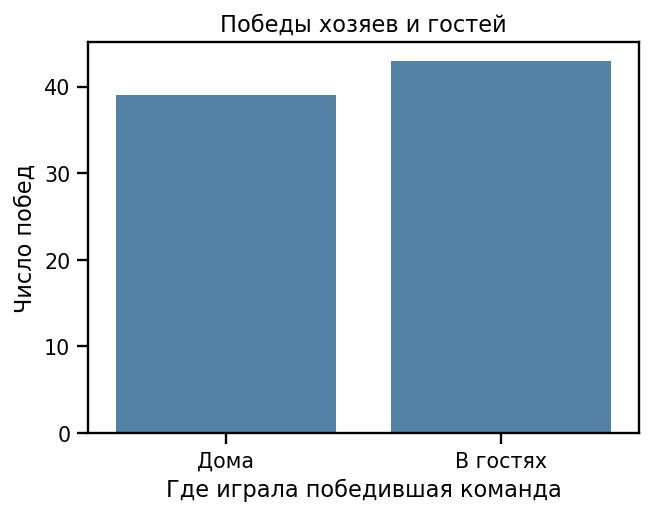

In [22]:
games['Home Win'] = games['Home Score'] > games['Away Score']
games['Overtime'] = games['Overtimes'] > 0
print('Побед хозяев:', games['Home Win'].sum())
print('Побед гостей:', (~games['Home Win']).sum())
print('Доля побед хозяев:', games['Home Win'].mean())
print('\nСреднее число голов:')
print(games[['Home Score', 'Away Score']].mean())

home_summary = games.groupby('Overtime')['Home Win'].agg(['count', 'sum', 'mean'])
home_summary.columns = ['Games', 'Home Wins', 'Home Win Share']
print('\nОтдельно по наличию овертайма:')
print(home_summary)

results = pd.DataFrame({'Площадка': ['Дома', 'В гостях'],
                        'Победы': [games['Home Win'].sum(), (~games['Home Win']).sum()]})
plt.figure(figsize=(5, 4))
sns.barplot(x='Площадка', y='Победы', data=results, color='steelblue')
plt.xlabel('Где играла победившая команда')
plt.ylabel('Число побед')
plt.title('Победы хозяев и гостей')
plt.tight_layout()
plt.show()

В этом наборе хозяева выиграли 39 матчей из 82, то есть 47,6%, а гости — 43.
Среднее число голов у хозяев 2,805, у гостей 3,122. Получается, простого
преимущества хозяев в итоговых показателях этой выборки не видно: гости
выигрывали немного чаще и в среднем забивали больше.

При этом группы различаются: в основное время хозяева выиграли 25 из 60
матчей (41,7%), а в играх с овертаймом — 14 из 22 (63,6%). Поэтому общий
итог не стоит автоматически переносить на каждый тип матча.

Это не означает, что домашняя площадка вообще не помогает. В данных один
плей-офф, команды различаются по силе, встречаются друг с другом сериями
и проводят неодинаковое число игр. Здесь сравнение описательное;
по нему нельзя отдельно оценить причинный эффект домашнего льда.